In [5]:
#1.1
import pandas as pd
from sklearn.model_selection import train_test_split
df = pd.read_excel("week10_students.xlsx")
print(df.shape)
print("correlation of score with quiz_avg : ",df["score"].corr(df["quiz_avg"]))
print("correlation of score with assignments_avg : ",df["score"].corr(df["assignments_avg"]))
print("correlation of score with attendance_pct : ",df["score"].corr(df["attendance_pct"]))

#Most useful is quiz_avg 

(150, 9)
correlation of score with quiz_avg :  0.8007262108513974
correlation of score with assignments_avg :  0.5359830904994728
correlation of score with attendance_pct :  0.23811757632601227


In [8]:
#1.2
x= df[["quiz_avg", "assignments_avg", "attendance_pct"]]
y = df[["score"]]
#1.2.b
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)
print("Train : ",len(x_train))
print("Test  : ",len(x_test))

Train :  112
Test  :  38


In [10]:
#2.1
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)
print(model.coef_, model.intercept_)
#there will be 0.58 points

[[0.57897954 0.364775   0.1133959 ]] [-4.42821334]


In [11]:
#2.2
from sklearn.metrics import (mean_absolute_error, r2_score)
pred= model.predict(x_test)
print(mean_absolute_error(y_test, pred)) #average we are off by
print(r2_score(y_test, pred))  #percentage of the differences in scores 

3.3291993077316526
0.886648735661214


In [12]:
#2.3
new_student = pd.DataFrame([[70, 75, 90]], columns=["quiz_avg","assignments_avg","attendance_pct"])
student= model.predict(new_student)
print("New student : ",student)
MyOwn= pd.DataFrame([[80, 85, 95]], columns=["quiz_avg","assignments_avg","attendance_pct"])
print("My own : ",model.predict(MyOwn))

New student :  [[73.66410989]]
My own :  [[83.66863472]]


In [15]:
#3.1.a
df["passed"]=(df["score"]>=50).astype(int)
print(df["passed"].value_counts())

passed
1    131
0     19
Name: count, dtype: int64


In [16]:
#3.1.b
from sklearn.linear_model import LogisticRegression
xc = df[["quiz_avg","assignments_avg","attendance_pct"]]
yc = df["passed"]
xc_train, xc_test, yc_train, yc_test = train_test_split(xc,yc, test_size = 0.25, random_state = 42)
clf = LogisticRegression(max_iter=1000)
clf.fit(xc_train, yc_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [18]:
#3.2.a
from sklearn.metrics import (accuracy_score, confusion_matrix)
y_pred_class = clf.predict(xc_test)
print("Model accuracy : ", accuracy_score(yc_test, y_pred_class))


Model accuracy :  0.8947368421052632


In [19]:
#3.2.b
print("Lazy baseline : ",yc_test.mean())


Lazy baseline :  0.8947368421052632


In [20]:
#3.2.c
print("confusion matrix : ", confusion_matrix(yc_test, y_pred_class))


confusion matrix :  [[ 3  1]
 [ 3 31]]


In [21]:
#3.2.d
#Model is not useless, because accuracy looks similar only because passes are 87% of data

In [22]:
#4
def evaluate_r2(x_):
    xt, xte, yt, yte = train_test_split(x, y, test_size=0.25, random_state=42)
    m= LinearRegression()
    m.fit(xt, yt)
    return r2_score(yte, m.predict(xte))
r_quiz_only = evaluate_r2(df[["quiz_avg"]])
r_all_three = evaluate_r2([["quiz_avg", "assignments_avg", "attendance_pct"]])
x_dummy = pd.get_dummies(df[["quiz_avg", "assignments_avg", "attendance_pct", "program"]], columns = ["program"])
r_with_program = evaluate_r2(x_dummy)
print(f"quiz only : {r_quiz_only:.4f}")
print(f"all three: {r_all_three:.4f}")
print(f"all three + program : {r_with_program:.4f}"),
#More features are not always better

quiz only : 0.8866
all three: 0.8866
all three + program : 0.8866


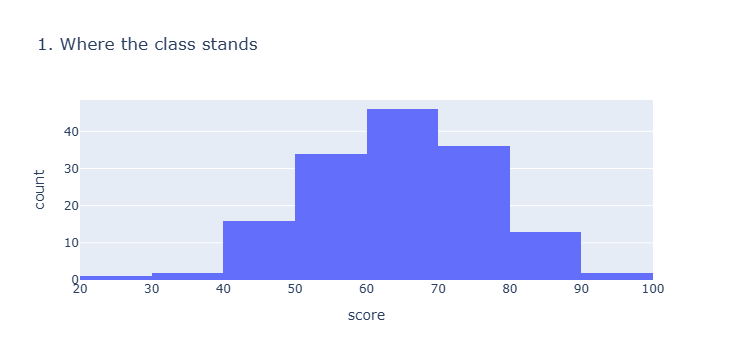

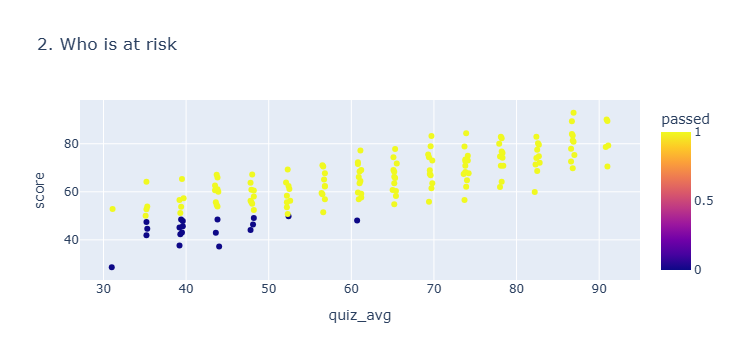

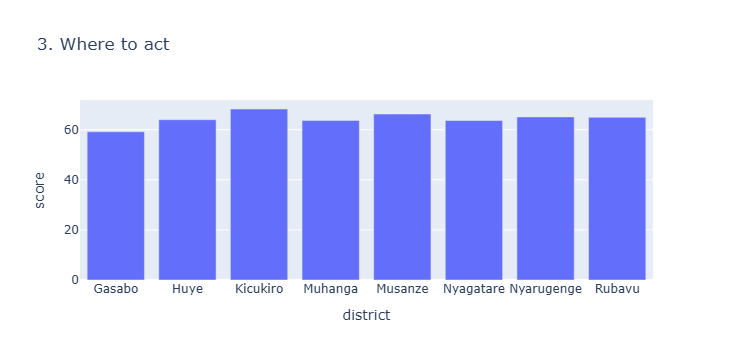

In [24]:
#5.1
import plotly.express as px
fig1 = px.histogram(df, x="score", nbins=12, title="1. Where the class stands")
fig1.show()

fig2 = px.scatter(df, x="quiz_avg", y="score", color="passed", hover_name="name", title="2. Who is at risk")
fig2.show()

avg_by_district = df.groupby("district", as_index=False)["score"].mean()
fig3=px.bar(avg_by_district, x="district", y="score", title="3. Where to act")
fig3.show()


In [25]:
#5.2
fig2.write_html("class_dashboard.html")

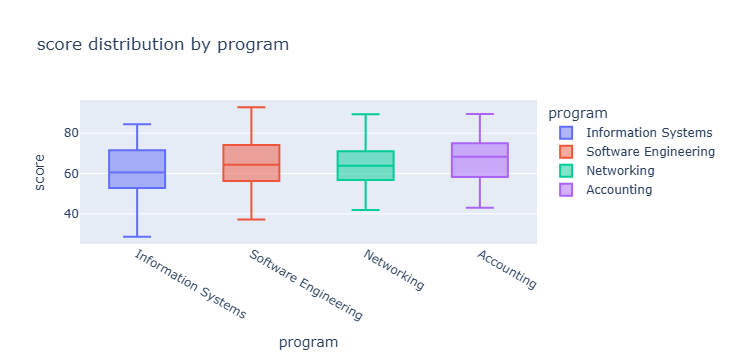

In [26]:
#bonus
fig1 = px.box(df, x="program", y="score", color="program", title="score distribution by program")
fig1.show()